In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv("../data/water_potability.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [3]:
X = df.drop(columns=["Potability"])
y = df["Potability"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [6]:
decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

In [7]:
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [8]:
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

In [9]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "SVM": svm_model
}

In [10]:
results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })


Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

Training SVM...


C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [11]:
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df)


Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.609756   0.000000  0.000000  0.000000
1        Decision Tree  0.596037   0.481328  0.453125  0.466801
2        Random Forest  0.663110   0.644628  0.304688  0.413793
3                  SVM  0.670732   0.704082  0.269531  0.389831


In [12]:
results_df[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
] = results_df[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].round(4)

print("\nRounded Results:")
print(results_df)


Rounded Results:
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.6098     0.0000  0.0000    0.0000
1        Decision Tree    0.5960     0.4813  0.4531    0.4668
2        Random Forest    0.6631     0.6446  0.3047    0.4138
3                  SVM    0.6707     0.7041  0.2695    0.3898


In [13]:
results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("\nResults saved successfully!")


Results saved successfully!


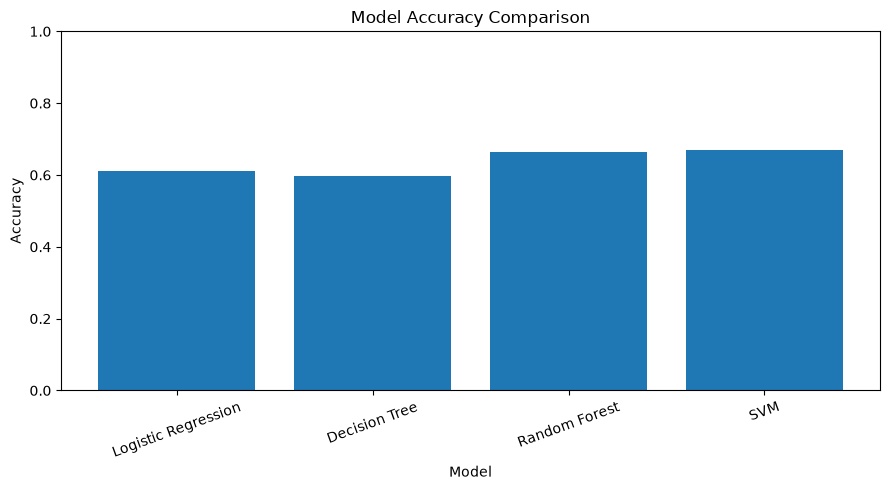

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

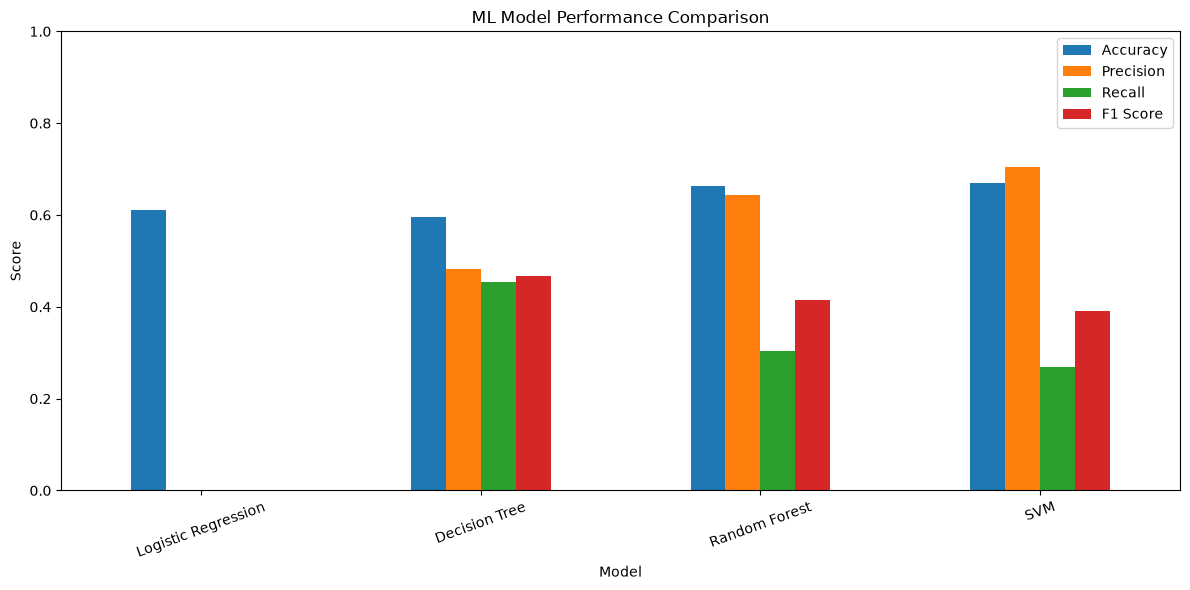

In [15]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("ML Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [16]:
print("\nFinal Comparison Table")
print("=" * 70)

print(
    results_df.to_string(index=False)
)


Final Comparison Table
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.6098     0.0000  0.0000    0.0000
      Decision Tree    0.5960     0.4813  0.4531    0.4668
      Random Forest    0.6631     0.6446  0.3047    0.4138
                SVM    0.6707     0.7041  0.2695    0.3898
